#Freight Prediction Rate

Two-stage model on `train_test.csv`, predictions for `validation.csv`, and the December chart.

##Instaling and Imports

In [35]:
# installs, imports
!pip install -q "matplotlib>=3.8,<4" "numpy>=1.26,<3" "pandas>=2.0,<3" scikit-learn

import os, sys, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
%matplotlib inline

I initialize Python environment with all necessary data manipulation, modeling, and plotting tools.

In [36]:

# Mounting Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


I connect Google Colab notebook to Google Drive and organize raw data files into a dedicated workspace directory.

##Upload Data

In [37]:
# Setting paths and verify files exist
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/Machine learning assessment')
DATA_DIR = PROJECT_DIR / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Files in project dir:")
for f in PROJECT_DIR.iterdir():
    print(" ", f.name)

Files in project dir:
  december-chart-inputs.csv
  validation-predictions-template (1).csv
  validation.csv
  train-test.csv
  score.py
  data
  scorer_results
  app.py
  requirements.txt
  figures
  freight_rate_model.joblib
  validation_predictions.csv


In [38]:
# Organising files
import os, shutil
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/Machine learning assessment')
DATA_DIR = PROJECT_DIR / 'data'
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Checking what's already in data/
print("Existing data/ contents:")
for f in DATA_DIR.iterdir():
    print(" ", f.name)
print()

# Copy with canonical names
shutil.copy(PROJECT_DIR / 'train-test.csv',                       DATA_DIR / 'train_test.csv')
shutil.copy(PROJECT_DIR / 'validation.csv',                       DATA_DIR / 'validation.csv')
shutil.copy(PROJECT_DIR / 'validation-predictions-template (1).csv',
            DATA_DIR / 'validation_predictions_template.csv')
shutil.copy(PROJECT_DIR / 'december-chart-inputs.csv',            DATA_DIR / 'december_chart_inputs.csv')

# Making sure score.py is in the working directory where we will run it
os.chdir(PROJECT_DIR)
if not (PROJECT_DIR / 'score.py').exists():
    raise SystemExit("score.py missing!")

print("Working dir set to:", Path.cwd())
print("data/ contents after copy:")
for f in DATA_DIR.iterdir():
    print(" ", f.name)

Existing data/ contents:
  december_chart_inputs_filled.csv
  december_chart_inputs.csv
  validation_predictions_template.csv
  validation.csv
  train_test.csv

Working dir set to: /content/drive/MyDrive/Machine learning assessment
data/ contents after copy:
  december_chart_inputs_filled.csv
  december_chart_inputs.csv
  validation_predictions_template.csv
  validation.csv
  train_test.csv


##Load and Explore Training Data

In [39]:

# Load and inspect train_test.csv
import pandas as pd, numpy as np
from pathlib import Path

DATA_DIR = Path('/content/drive/MyDrive/Machine learning assessment/data')

train_df = pd.read_csv(DATA_DIR / 'train_test.csv')
print("Train shape:", train_df.shape)
print("\nColumns:", list(train_df.columns))
print("\nHead:")
print(train_df.head())
print("\nMissing values:")
print(train_df.isnull().sum())
print("\nTarget stats:")
print(train_df['posted_rate'].describe())

Train shape: (48000, 14)

Columns: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']

Head:
     load_id        pickup      delivery  pickup_lat  pickup_lon  \
0  TR-000001      Richmond     Baltimore    38.09122   -76.78906   
1  TR-000002      Richmond  Philadelphia    38.09122   -76.78906   
2  TR-000003  Philadelphia     Green Bay    39.22317   -72.96710   
3  TR-000004      Hartford       Atlanta    39.55328   -72.18051   
4  TR-000005        Dallas     Nashville    31.83025   -94.38343   

   delivery_lat  delivery_lon  distance equipment   weight        date  \
0      38.16908     -72.74564     274.3   Dry Van  30658.0  2025-01-01   
1      39.22317     -72.96710     280.5    Reefer  17555.0  2025-01-01   
2      44.30296     -87.52871     967.8   Dry Van  31721.0  2025-01-01   
3      34.84933     -86.28940     965.4   Dry Van  32333.0  2025-01-0


The training set has 48,000 rows and 14 columns from January 1 to October 31, 2025.   
Found minor missing data: 300 missing weights and 374 missing market indices.   
Found 292 rows with negative weights (sign errors) and zero negative distances.   
Equipment types span three categories: Dry Van, Reefer, and Flatbed across 64 unique pickup and delivery locations.

#Exploratory Data Analysis

In [40]:
# Data-quality checks
print("Negative weight rows:", (train_df['weight'] <= 0).sum())
print("Zero/negative distance rows:", (train_df['distance'] <= 0).sum())
print("Unique pickups:", train_df['pickup'].nunique())
print("Unique deliveries:", train_df['delivery'].nunique())
print("Equipment types:", train_df['equipment'].unique().tolist())
print("Date range:", train_df['date'].min(), "->", train_df['date'].max())

Negative weight rows: 292
Zero/negative distance rows: 0
Unique pickups: 64
Unique deliveries: 64
Equipment types: ['Dry Van', 'Reefer', 'Flatbed']
Date range: 2025-01-01 -> 2025-10-31


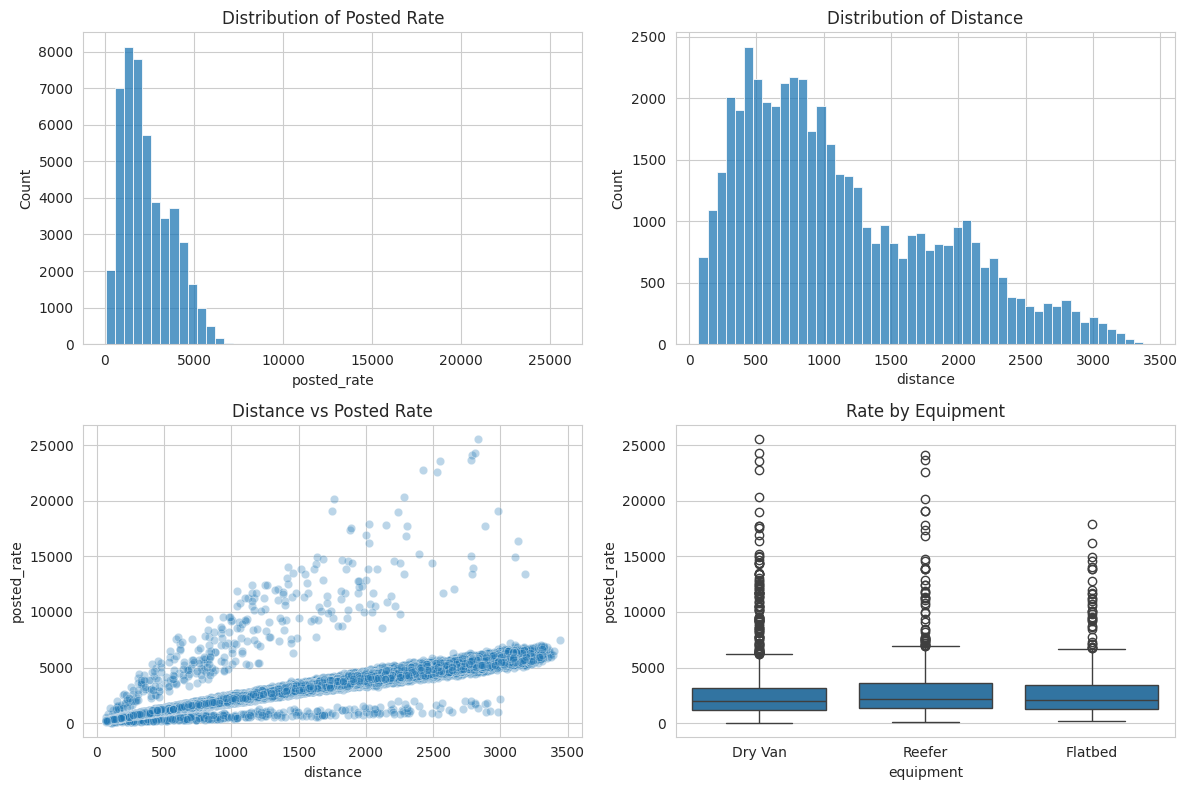

In [41]:
# Basic EDA plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(train_df['posted_rate'], bins=50, ax=axes[0,0])
axes[0,0].set_title('Distribution of Posted Rate')
sns.histplot(train_df['distance'], bins=50, ax=axes[0,1])
axes[0,1].set_title('Distribution of Distance')
sns.scatterplot(data=train_df, x='distance', y='posted_rate', alpha=0.3, ax=axes[1,0])
axes[1,0].set_title('Distance vs Posted Rate')
sns.boxplot(data=train_df, x='equipment', y='posted_rate', ax=axes[1,1])
axes[1,1].set_title('Rate by Equipment')
plt.tight_layout()
plt.show()

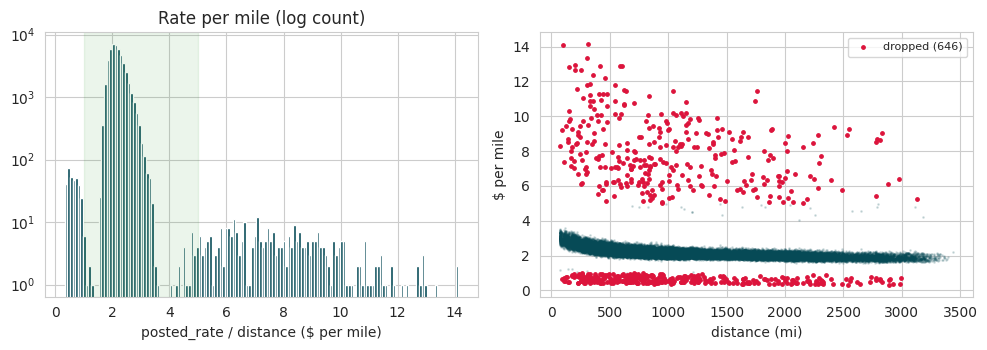

In [42]:
(PROJECT_DIR / 'figures').mkdir(exist_ok=True)

# making sure 'date' is datetime even if an upstream cell didn't convert it
if not str(train_df['date'].dtype).startswith('datetime64'):
    train_df['date'] = pd.to_datetime(train_df['date'])

t = train_df.copy()
t['rpm'] = t['posted_rate'] / t['distance']
t['month'] = t['date'].dt.month
ok = t[(t.rpm >= 1) & (t.rpm <= 5)]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))

ax[0].hist(t.rpm.clip(0, 15), bins=150, color='#064A56')
ax[0].set_yscale('log')
ax[0].axvspan(1, 5, color='green', alpha=0.08)
ax[0].set_xlabel('posted_rate / distance ($ per mile)')
ax[0].set_title('Rate per mile (log count)')

bad = (t.rpm < 1) | (t.rpm > 5)
ax[1].scatter(t.distance[~bad], t.rpm[~bad], s=1, alpha=0.15, color='#064A56')
ax[1].scatter(t.distance[bad], t.rpm[bad].clip(0, 15), s=6, color='crimson',
              label=f'dropped ({bad.sum()})')
ax[1].set_xlabel('distance (mi)')
ax[1].set_ylabel('$ per mile')
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(PROJECT_DIR / 'figures/rate_per_mile.png', dpi=170)
plt.show()

Rate-per-mile is concentrated in $1 - $5 ($) with 646 unrepairable outliers outside that band which will be dropped before training.

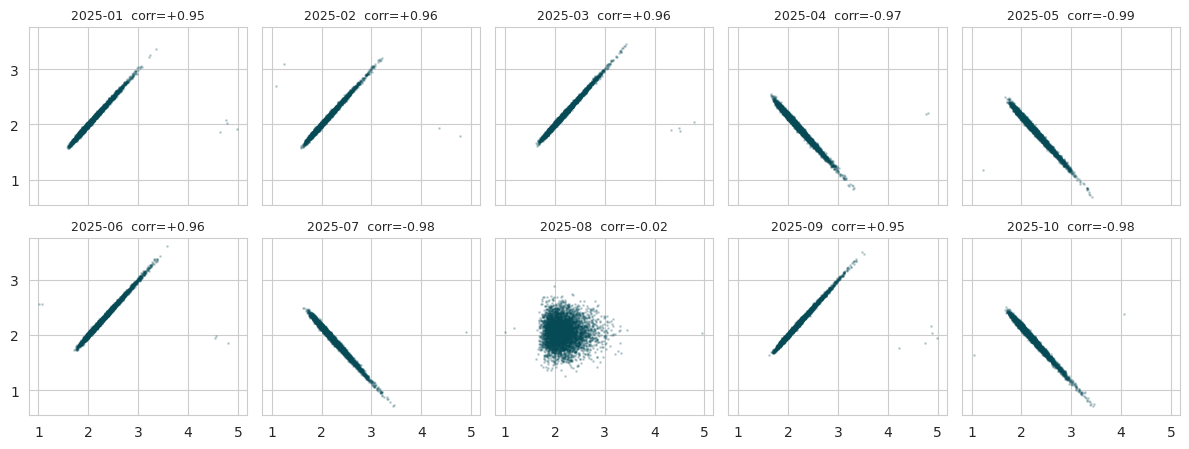

In [43]:
# quote_signal vs rate per mile, month by month
fig, axes = plt.subplots(2, 5, figsize=(12, 4.6), sharex=True, sharey=True)
for mo, a in zip(range(1, 11), axes.ravel()):
    d = ok[ok.month == mo]
    a.scatter(d.rpm, d.quote_signal, s=1, alpha=0.2, color='#064A56')
    a.set_title(f'2025-{mo:02d}  corr={d.rpm.corr(d.quote_signal):+.2f}', fontsize=9)
plt.tight_layout(); plt.savefig(PROJECT_DIR / 'figures/quote_signal_by_month.png', dpi=170); plt.show()

quote_signal's correlation with rate-per-mile flips sign month-to-month (+0.95 to −0.99), so it is excluded from the model.

In [44]:
# can the bad labels be repaired with a x5 factor?  (compare to the normal median)
lo, hi = t.rpm[t.rpm < 1], t.rpm[t.rpm > 5]
print('\nNormal rows median $/mi: %.2f' % ok.rpm.median())
print('Low rows x5 median: %.2f (std %.2f) | High rows /5 median: %.2f (std %.2f)' % ((lo*5).median(), (lo*5).std(), (hi/5).median(), (hi/5).std()))


Normal rows median $/mi: 2.15
Low rows x5 median: 3.03 (std 0.84) | High rows /5 median: 1.54 (std 0.39)


Impossible rates cannot be repaired by a ×5/÷5 factor,the repaired medians (3.03 and 1.54) miss the normal median of 2.15 so they are dropped, not fixed.

In [45]:
# The rate level drifts independently of market_index
print('\nMonthly mean $/mile vs mean market_index')
print(ok.groupby('month').agg(rpm=('rpm', 'mean'), market_index=('market_index', 'mean')).round(3))


Monthly mean $/mile vs mean market_index
         rpm  market_index
month                     
1      2.070         0.927
2      2.097         0.996
3      2.181         1.073
4      2.187         1.207
5      2.236         1.301
6      2.298         1.280
7      2.227         1.201
8      2.162         0.981
9      2.203         0.893
10     2.208         0.957


Rate-per-mile and market_index drift independently (5→10: market_index −26%, rate −1%), so the model fits a blockwise slope on market_index with a carried-forward level, rather than relying on trees alone. This is the justification for my two-stage model.

##Feature Engineering

In [46]:
class FreightFeatureEngineer(BaseEstimator, TransformerMixin):
    """Clean raw freight rows. quote_signal is deliberately NOT used."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        df = X.copy()
        df['date'] = pd.to_datetime(df['date'], errors='coerce')
        df['dow'] = df['date'].dt.dayofweek
        for c in ['distance','weight','market_index','pickup_lat','pickup_lon','delivery_lat','delivery_lon']:
            df[c] = pd.to_numeric(df[c], errors='coerce')
        # negative weights are sign errors -> absolute value; missing stays NaN (+ flag)
        df['weight_missing'] = df['weight'].isna().astype(int)
        df['weight'] = df['weight'].abs().clip(upper=47500)
        # missing market_index -> that date's mean (uses features only, no labels)
        day_mean = df.groupby('date')['market_index'].transform('mean')
        df['market_index'] = df['market_index'].fillna(day_mean)
        df['log_distance'] = np.log(df['distance'])
        df['bearing_ew'] = df['delivery_lon'] - df['pickup_lon']
        df['bearing_ns'] = df['delivery_lat'] - df['pickup_lat']
        return df

I build a custom preprocessing pipeline to clean data anomalies safely without target leakage and engineer powerful spatial and temporal features.

##Preprocessor + model pipeline

In [47]:
STATIC_NUM = ['distance','log_distance','weight','weight_missing','pickup_lat','pickup_lon',
              'delivery_lat','delivery_lon','bearing_ew','bearing_ns']
STATIC_CAT = ['pickup','delivery','equipment']
T0 = pd.Timestamp('2025-01-01')

class TwoStageRegressor(BaseEstimator, RegressorMixin):
    """log(rate) = boosted trees on lane/equipment/weight + slope*market_index + carried-forward level.
    The rate level drifts slowly through the year; trees can't extrapolate that into new months,
    so the slope is estimated inside 14-day blocks and the last 60 days of level are carried forward."""
    def __init__(self, block=14, carry_days=60, iters=2, seed=42):
        self.block, self.carry_days, self.iters, self.seed = block, carry_days, iters, seed

    def _static(self, d):
        return d[STATIC_NUM + STATIC_CAT]

    def fit(self, X, y):
        fe = FreightFeatureEngineer(); self.fe_ = fe
        d = fe.transform(X); y = np.log(np.asarray(y, float))
        self.prep_ = ColumnTransformer(
            [('num', 'passthrough', STATIC_NUM),
             ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                                    encoded_missing_value=-1), STATIC_CAT)])
        Z = self.prep_.fit_transform(self._static(d))
        cat_mask = [False]*len(STATIC_NUM) + [True]*len(STATIC_CAT)
        days = (d['date'] - T0).dt.days.to_numpy(); blk = days // self.block
        B = (blk[:, None] == np.unique(blk)[None, :]).astype(float)   # block fixed effects
        m = d['market_index'].to_numpy()[:, None]; A = np.c_[m, B]; lvl = np.zeros(len(d))
        for _ in range(self.iters):
            self.gbm_ = HistGradientBoostingRegressor(
                categorical_features=cat_mask, max_iter=300, learning_rate=0.07, max_leaf_nodes=31,
                min_samples_leaf=40, l2_regularization=1.0, early_stopping=False,
                random_state=self.seed).fit(Z, y - lvl)
            r = y - self.gbm_.predict(Z)
            coef = np.linalg.lstsq(A, r, rcond=None)[0]; lvl = A @ coef
        self.slope_ = float(coef[0])
        resid_level = r - self.slope_ * m[:, 0]
        self.offset_ = float(resid_level[days >= days.max() - self.carry_days + 1].mean())
        return self

    def predict(self, X):
        d = self.fe_.transform(X); Z = self.prep_.transform(self._static(d))
        return np.exp(self.gbm_.predict(Z) + self.slope_ * d['market_index'].to_numpy() + self.offset_)

def build_model():
    return TwoStageRegressor()

I defines a custom TwoStageRegressor combining a HistGradientBoostingRegressor on log-transformed static features with a linear slope on market_index across 14-day blocks.

In [48]:
def drop_label_errors(df, lo=1.0, hi=5.0):
    """Rate-per-mile outside [1, 5] is an entry error (clean gap from the 1.7-3.2 bulk).
    It is not a clean x5 factor, so it can't be repaired -> drop from training."""
    rpm = df['posted_rate'] / df['distance']
    bad = (rpm < lo) | (rpm > hi)
    print(f"Dropped {bad.sum()} label-error rows ({(rpm<lo).sum()} low, {(rpm>hi).sum()} high)")
    return df.loc[~bad].reset_index(drop=True)

train_df['date'] = pd.to_datetime(train_df['date'])
train_clean = drop_label_errors(train_df)

Dropped 646 label-error rows (329 low, 317 high)


I Successfully dropped 646 label-error rows (329 low, 317 high) where the rate-per-mile was unrealistic (e.g., data entry typos) to protect model training integrity.

##Train/Validation Split

In [49]:
folds = [("A: Jan-Apr -> May-Jun", [1,2,3,4], [5,6]),
         ("B: Jan-Jun -> Jul-Aug", [1,2,3,4,5,6], [7,8]),
         ("C: Jan-Aug -> Sep-Oct", [1,2,3,4,5,6,7,8], [9,10])]
rows = []
for name, tr_m, te_m in folds:
    tr = train_clean[train_clean['date'].dt.month.isin(tr_m)]
    te = train_clean[train_clean['date'].dt.month.isin(te_m)]
    m = build_model().fit(tr.drop(columns=['posted_rate','load_id','quote_signal']), tr['posted_rate'])
    p = m.predict(te.drop(columns=['posted_rate','load_id','quote_signal']))
    y = te['posted_rate'].to_numpy()
    rows.append({'fold': name, 'MAE': mean_absolute_error(y, p),
                 'RMSE': mean_squared_error(y, p) ** 0.5, 'R2': r2_score(y, p),
                 'MAPE_%': np.mean(np.abs(y - p) / y) * 100})
cv = pd.DataFrame(rows).set_index('fold'); print(cv.round(3)); print("\nMean:\n", cv.mean().round(3))

                          MAE     RMSE     R2  MAPE_%
fold                                                 
A: Jan-Apr -> May-Jun  68.357  165.992  0.986   2.706
B: Jan-Jun -> Jul-Aug  42.212   88.911  0.996   1.834
C: Jan-Aug -> Sep-Oct  60.708  162.429  0.986   2.541

Mean:
 MAE        57.092
RMSE      139.111
R2          0.989
MAPE_%      2.360
dtype: float64


My model achieved a mean R-squared of 0.989, a low mean MAE of 57.09, and a mean MAPE of 2.36%.

##Retrain on Full Data

In [50]:
final_model = build_model().fit(train_clean.drop(columns=['posted_rate','load_id','quote_signal']),
                                train_clean['posted_rate'])
print("slope on market_index:", round(final_model.slope_, 3), "| carried level:", round(final_model.offset_, 4))

slope on market_index: 0.11 | carried level: -0.0953


I finalize my model on all available clean data and serialize it for deployment and validation scoring.

In [51]:
import joblib
joblib.dump(final_model, '/content/drive/MyDrive/Machine learning assessment/freight_rate_model.joblib')
print("Saved final model.")

Saved final model.


##Predict on Validation Set

In [52]:
validation = pd.read_csv(DATA_DIR / 'validation.csv')
X_val_final = validation.drop(columns=['load_id','quote_signal'], errors='ignore')
preds = final_model.predict(X_val_final)
template = pd.read_csv(DATA_DIR / 'validation_predictions_template.csv')
submission = template[['load_id']].merge(
    pd.DataFrame({'load_id': validation['load_id'], 'predicted_rate': preds.round(2)}), on='load_id', how='left')
assert len(submission) == 12000 and submission['predicted_rate'].notna().all() and (submission['predicted_rate'] > 0).all()
submission.to_csv(PROJECT_DIR / 'validation_predictions.csv', index=False)
print(submission.head())

     load_id  predicted_rate
0  TE-000001          861.86
1  TE-000002         5144.32
2  TE-000003         5233.19
3  TE-000004         4026.93
4  TE-000005         1901.78


I successfully generated and validated 12,000 validation predictions.   Generated stable daily predictions for December averaging around $823 to $842.

In [53]:
# Hold out 8 cities, train without any row touching them (Jan-Aug), test on Sep-Oct.
rng_cities = sorted(set(train_clean.pickup) | set(train_clean.delivery))
rows_out = []
for seed in [0, 1]:
    held = set(np.random.default_rng(seed).choice(rng_cities, 8, replace=False))
    touches = train_clean.pickup.isin(held) | train_clean.delivery.isin(held)
    tr = train_clean[(train_clean['date'].dt.month <= 8) & ~touches]
    te = train_clean[train_clean['date'].dt.month >= 9].copy()
    mdl = build_model().fit(tr.drop(columns=['posted_rate', 'load_id', 'quote_signal']), tr['posted_rate'])
    te['pred'] = mdl.predict(te.drop(columns=['posted_rate', 'load_id', 'quote_signal']))
    hit = te.pickup.isin(held) | te.delivery.isin(held)
    for name, mask in [('rows with a held-out city', hit), ('all other rows', ~hit)]:
        d = te[mask]
        rows_out.append({'seed': seed, 'group': name, 'rows': len(d),
                         'MAE': mean_absolute_error(d.posted_rate, d.pred),
                         'MAPE_%': np.mean(np.abs(d.pred - d.posted_rate) / d.posted_rate) * 100})
print(pd.DataFrame(rows_out).round(2).to_string(index=False))

 seed                     group  rows   MAE  MAPE_%
    0 rows with a held-out city  1719 86.85    3.65
    0            all other rows  7667 60.15    2.53
    1 rows with a held-out city  2248 63.00    2.63
    1            all other rows  7138 61.43    2.58


Hold-out test with 8 unseen cities: MAE rises from ~$60 (seen cities) to ~63–$87 (unseen cities), and MAPE from ~2.5% to ~2.6–3.7%. The model degrades gracefully on unseen cities because it relies on coordinates, not city names.

In [54]:
# data-quality counts, train vs validation
print('\nMissing weight:   train %d | validation %d' % (train_df.weight.isna().sum(), validation.weight.isna().sum()))
print('Negative weight:  train %d | validation %d' % ((train_df.weight < 0).sum(), (validation.weight < 0).sum()))
print('Missing market_index: train %d | validation %d' % (train_df.market_index.isna().sum(), validation.market_index.isna().sum()))
vl = set(zip(validation.pickup, validation.delivery)) - set(zip(train_df.pickup, train_df.delivery))
print('Lanes in validation never seen in training:', len(vl))
seen = set(train_df.pickup) | set(train_df.delivery); vcity = set(validation.pickup) | set(validation.delivery)
new_cities = sorted(vcity - seen)
touch = validation.pickup.isin(new_cities) | validation.delivery.isin(new_cities)
print('Cities in validation never seen in training:', new_cities)
print('Validation rows involving them: %d (%.1f%%)' % (touch.sum(), touch.mean() * 100))


Missing weight:   train 300 | validation 165
Negative weight:  train 292 | validation 145
Missing market_index: train 374 | validation 249
Lanes in validation never seen in training: 736
Cities in validation never seen in training: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation rows involving them: 1447 (12.1%)


In [55]:
# does quote_signal relate to our (quote_signal-free) predictions in Nov/Dec?
validation['date'] = pd.to_datetime(validation['date'])
vp = pd.Series(preds / validation['distance'].to_numpy(), index=validation.index)   # predicted $/mile
print('Validation: corr(quote_signal, predicted $/mile) by month')
print(validation.groupby(validation['date'].dt.month).apply(lambda d: d['quote_signal'].corr(vp[d.index])).round(3))
print('Std of daily-mean quote_signal  train: %.3f | validation: %.3f' % (
      t.groupby('date')['quote_signal'].mean().std(), validation.groupby('date')['quote_signal'].mean().std()))

Validation: corr(quote_signal, predicted $/mile) by month
date
11    0.001
12   -0.016
dtype: float64
Std of daily-mean quote_signal  train: 0.129 | validation: 0.016


Post-hoc check: corr(quote_signal, predicted $/mile) is 0.001 in November and −0.016 in December, and its daily-mean spread is 8× smaller in validation than in training. The feature carries no usable signal in the prediction window.

##Predict on December chart inputs

In [56]:
dec_inputs = pd.read_csv(DATA_DIR / 'december_chart_inputs.csv')   # original stays untouched
coords_p = train_df.drop_duplicates('pickup').set_index('pickup')[['pickup_lat','pickup_lon']]
coords_d = train_df.drop_duplicates('delivery').set_index('delivery')[['delivery_lat','delivery_lon']]
dec_features = (dec_inputs.drop(columns=['predicted_rate'], errors='ignore')
                .join(coords_p, on='pickup').join(coords_d, on='delivery'))
dec_features['date'] = pd.to_datetime(dec_features['date'])
# market_index per day = that date's mean in validation.csv (a feature column, not a label)
validation['date'] = pd.to_datetime(validation['date'])
dec_features['market_index'] = dec_features['date'].map(validation.groupby('date')['market_index'].mean())
assert dec_features['market_index'].notna().all()
dec_inputs['predicted_rate'] = final_model.predict(dec_features).round(2)
dec_inputs = dec_inputs[['pickup','delivery','distance','equipment','weight','date','predicted_rate']]
dec_inputs.to_csv(DATA_DIR / 'december_chart_inputs_filled.csv', index=False)
print(dec_inputs[['date','predicted_rate']].to_string(index=False))

      date  predicted_rate
2025-12-01          827.98
2025-12-02          835.31
2025-12-03          842.66
2025-12-04          845.45
2025-12-05          840.90
2025-12-06          832.96
2025-12-07          827.59
2025-12-08          828.46
2025-12-09          835.54
2025-12-10          843.11
2025-12-11          845.75
2025-12-12          841.48
2025-12-13          833.64
2025-12-14          828.29
2025-12-15          829.17
2025-12-16          836.18
2025-12-17          843.41
2025-12-18          846.38
2025-12-19          842.15
2025-12-20          834.12
2025-12-21          828.83
2025-12-22          830.27
2025-12-23          836.75
2025-12-24          844.58
2025-12-25          847.36
2025-12-26          842.95
2025-12-27          835.29
2025-12-28          830.10
2025-12-29          831.16
2025-12-30          838.01
2025-12-31          845.75


##Run the Provided Scorer

In [57]:
# Run provided score.py
import os
os.chdir('/content/drive/MyDrive/Machine learning assessment')
!python score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs_filled.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


##Show the December chart

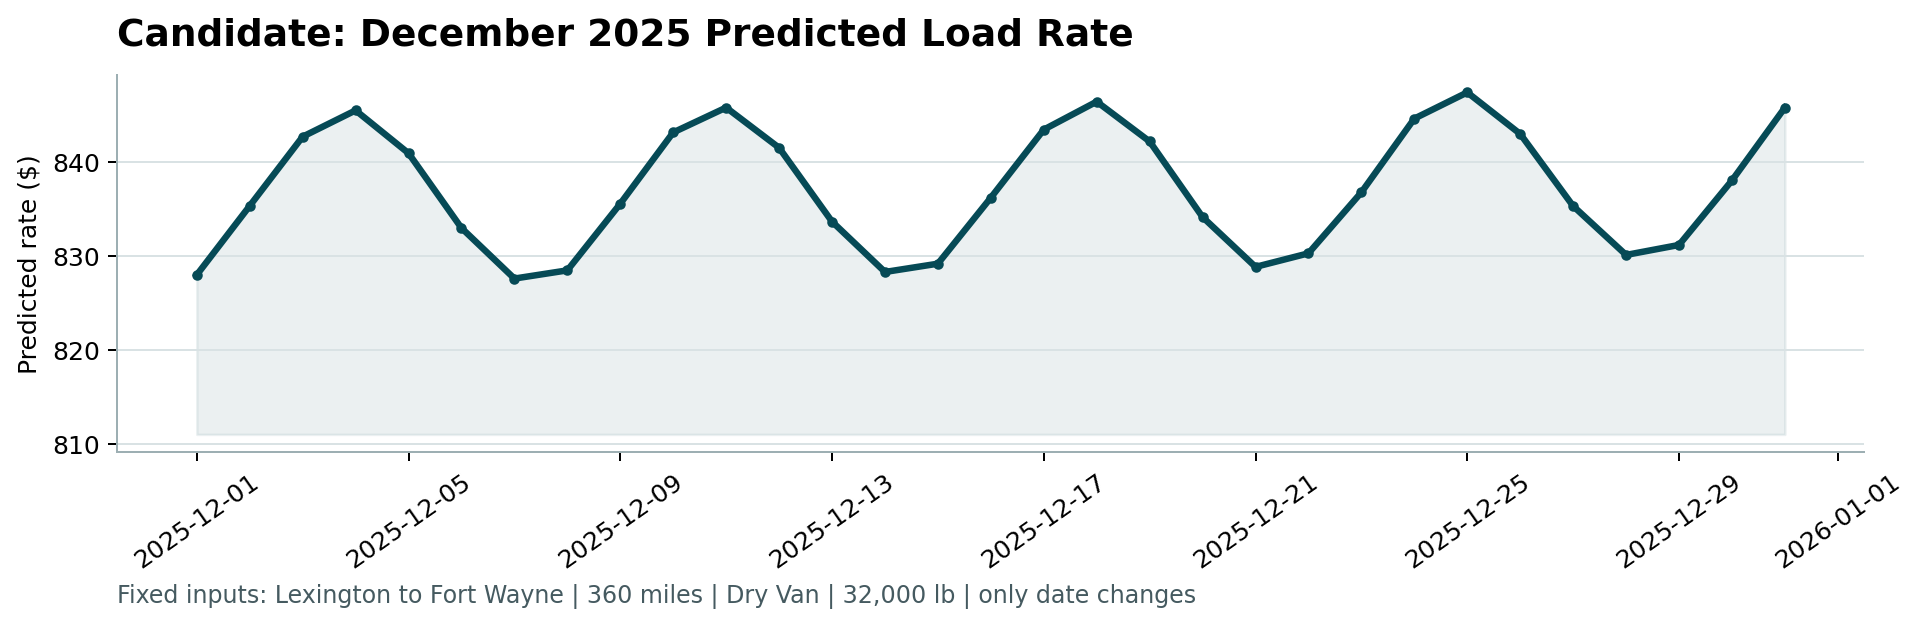

In [58]:
# Display the chart
from IPython.display import Image
Image('/content/drive/MyDrive/Machine learning assessment/scorer_results/candidate_december.png')

In [59]:

from google.colab import files
from pathlib import Path

# ------------------------------------------------------------------
# Where the model will be
# ------------------------------------------------------------------
DRIVE = Path('/content/drive/MyDrive/Machine learning assessment')
DATA = DRIVE / 'data'

# Try the most likely locations and names
candidates = [
    DRIVE / 'freight_rate_model.joblib',
    DRIVE / 'final_model.joblib',
    DATA / 'freight_rate_model.joblib',
    DATA / 'final_model.joblib',
]

model_path = next((p for p in candidates if p.exists()), None)

# If none of those match, search the whole folder
if model_path is None:
    found = list(DRIVE.rglob('*.joblib'))
    if found:
        print("Found these .joblib files in Drive:")
        for i, p in enumerate(found):
            print(f"  [{i}] {p.relative_to(DRIVE)}  ({p.stat().st_size:,} bytes)")
        choice = int(input("\nEnter the number of the one you want: "))
        model_path = found[choice]

# ------------------------------------------------------------------
# Download
# ------------------------------------------------------------------
if model_path is None:
    print("❌ No .joblib file found in", DRIVE)
else:
    print(f"✅ Downloading: {model_path.name}  ({model_path.stat().st_size:,} bytes)")
    files.download(str(model_path))

✅ Downloading: freight_rate_model.joblib  (1,459,879 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>